In [345]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

Libraries imported successfully!


In [346]:
import numpy as np
import pandas as pd
np.random.seed(42)
n = 200
study_hours = np.random.uniform(1, 10,n)
attendence = np.random.uniform(50,100,n)
previous_marks = np.random.uniform(35,95,n)
sleep_hours = np.random.uniform(4,10,n)

final_marks =  (
    study_hours * 4
    + attendence * 0.2
    + previous_marks * 0.3
    + sleep_hours * 1.5
    + np.random.normal(0, 5 , n)

)

final_marks + np.clip(final_marks , 0, 100 )
df = pd.DataFrame({
    "Study_Hours":
    study_hours.round(1),
    "Attendence":
    attendence.round(1),
    "Previous_Marks":
    previous_marks.round(1),
    "Sleep_Hours":
  sleep_hours.round(1),
    "Final_Marks":
    final_marks.round(1)

})



In [347]:
# Display first 5 students
print("First 5 Students:")
print(df.head())

# Display total rows and columns
print("Dataset Shape:", df.shape)

# Display all column names
print("Column Names:", df.columns)

First 5 Students:
   Study_Hours  Attendence  Previous_Marks  Sleep_Hours  Final_Marks
0          4.4        82.1            41.2          5.0         49.8
1          9.6        54.2            89.2          5.7         86.7
2          7.6        58.1            65.3          5.1         78.6
3          6.4        94.9            84.6          4.5         83.4
4          2.4        80.3            54.2          4.7         57.0
Dataset Shape: (200, 5)
Column Names: Index(['Study_Hours', 'Attendence', 'Previous_Marks', 'Sleep_Hours',
       'Final_Marks'],
      dtype='object')


In [348]:
print("Missing Value:")
print(df.isnull().sum())

Missing Value:
Study_Hours       0
Attendence        0
Previous_Marks    0
Sleep_Hours       0
Final_Marks       0
dtype: int64


In [349]:
print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Study_Hours     200 non-null    float64
 1   Attendence      200 non-null    float64
 2   Previous_Marks  200 non-null    float64
 3   Sleep_Hours     200 non-null    float64
 4   Final_Marks     200 non-null    float64
dtypes: float64(5)
memory usage: 7.9 KB
None

Statistical Summary:
       Study_Hours  Attendence  Previous_Marks  Sleep_Hours  Final_Marks
count   200.000000   200.00000      200.000000   200.000000   200.000000
mean      5.358500    75.21900       66.242000     6.873500    66.603000
std       2.655842    14.64782       18.438676     1.674385    13.286536
min       1.000000    50.30000       35.700000     4.100000    34.400000
25%       3.100000    63.10000       50.325000     5.400000    56.950000
50%       5.450000    77.05000       66.550000     6.80

                Study_Hours  Attendence  Previous_Marks  Sleep_Hours  \
Study_Hours        1.000000   -0.027762       -0.044721    -0.034421   
Attendence        -0.027762    1.000000       -0.123967     0.070627   
Previous_Marks    -0.044721   -0.123967        1.000000     0.060740   
Sleep_Hours       -0.034421    0.070627        0.060740     1.000000   
Final_Marks        0.804972    0.112402        0.359451     0.170867   

                Final_Marks  
Study_Hours        0.804972  
Attendence         0.112402  
Previous_Marks     0.359451  
Sleep_Hours        0.170867  
Final_Marks        1.000000  


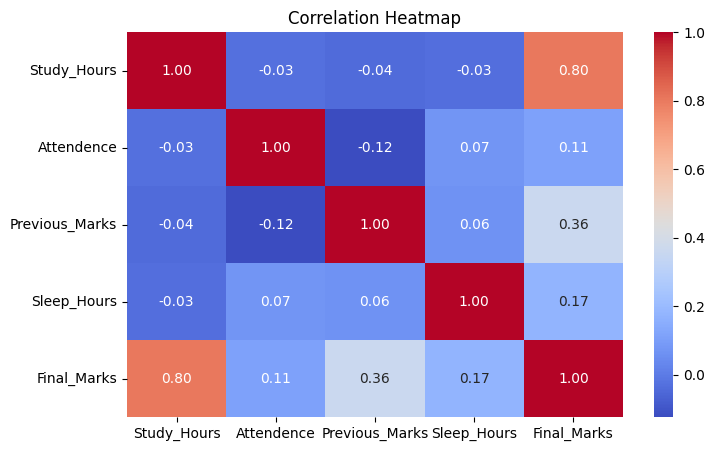

In [350]:
correlation = df.corr(numeric_only=True)

print(correlation)

plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [351]:
# Feature Selection
X = df[["Study_Hours", "Attendence","Previous_Marks","Sleep_Hours"]]
y = df["Final_Marks"]

print("Iput Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Iput Features:
   Study_Hours  Attendence  Previous_Marks  Sleep_Hours
0          4.4        82.1            41.2          5.0
1          9.6        54.2            89.2          5.7
2          7.6        58.1            65.3          5.1
3          6.4        94.9            84.6          4.5
4          2.4        80.3            54.2          4.7

Target Values:
0    49.8
1    86.7
2    78.6
3    83.4
4    57.0
Name: Final_Marks, dtype: float64


In [352]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.2, random_state=42
)

print("Training Data:" , X_train.shape)
print("Testing Data:" , X_test.shape)
print("Training Target:" , y_train.shape)
print("Testing Tareget:", y_test.shape)


Training Data: (160, 4)
Testing Data: (40, 4)
Training Target: (160,)
Testing Tareget: (40,)


In [353]:
from sklearn.linear_model import LinearRegression
# Create Model
model = LinearRegression()
# Train Model
model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [354]:
from sklearn.metrics import mean_absolute_error , mean_squared_error, r2_score
import numpy as np

# Predict Test Data
y_pred = model.predict(X_test)

# Evalute Model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test , y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squard Error:" , mse)
print("Root Mean Squared Error:" , rmse)
print("R2 Score:", r2)


Mean Absolute Error: 3.7027912221443673
Mean Squard Error: 20.681128509433606
Root Mean Squared Error: 4.547650878138471
R2 Score: 0.8941866270582284


In [355]:
# Predict marks for a new student

new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendence": [85],
    "Previous_Marks": [75],
    "Sleep_Hours": [7]
})


predicted_marks = model.predict(new_student)

print("Predicted Final Marks:", round(predicted_marks[0], 2))

Predicted Final Marks: 73.3
